In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

# Importing Libraries and Selecting the Device

In [2]:
import os
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets, transforms
from torch.utils.data import DataLoader, random_split
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


# Checking the dataset path

In [50]:
dataset_path = "/kaggle/input/datasets/saymaakterrithy/grapesleaf/Niphad Grape Leaf Disease Dataset (NGLD)"

print(os.listdir(dataset_path))

['Grapes Disease Dataset']


# Counting images in every class

In [53]:

import os

dataset_path = "/kaggle/input/datasets/saymaakterrithy/grapesleaf/Niphad Grape Leaf Disease Dataset (NGLD)"

# Find all folders and images
total_images = 0

for root, dirs, files in os.walk(dataset_path):

    image_files = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if image_files:
        print(os.path.basename(root), ":", len(image_files))
        total_images += len(image_files)

print("\nTotal Images:", total_images)


Bacterial Rot : 100
Downey Mildew : 966
Healthy Leaves : 1254
Powdery Mildew : 406

Total Images: 2726


# Listing the available Kaggle input folders

In [55]:
import os

print("Available Kaggle Input Folders:\n")

for folder in os.listdir("/kaggle/input"):
    print(folder)

Available Kaggle Input Folders:

datasets


# Locating the class-folder root automatically

In [56]:
import os

search_root = "/kaggle/input"

source_dir = None

for root, dirs, files in os.walk(search_root):

    if os.path.basename(root).lower() == "grapes disease dataset":
        source_dir = root
        break

if source_dir is not None:

    print("Dataset Found!")
    print("Source Directory:", source_dir)
    print("Classes:", os.listdir(source_dir))

else:
    print("Dataset folder not found!")
    print("Please check the available folders:")
    print(os.listdir(search_root))

Dataset Found!
Source Directory: /kaggle/input/datasets/saymaakterrithy/grapesleaf/Niphad Grape Leaf Disease Dataset (NGLD)/Grapes Disease Dataset
Classes: ['Bacterial Rot', 'Downey Mildew', 'Healthy Leaves', 'Powdery Mildew']


# Train / Validation / Test split, transforms and DataLoaders

In [58]:
import os
import shutil
import torch
from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ---------------- SETTINGS ----------------

IMG_SIZE = 128
BATCH_SIZE = 32

# Correct Dataset Path
source_dir = "/kaggle/input/datasets/saymaakterrithy/grapesleaf/Niphad Grape Leaf Disease Dataset (NGLD)/Grapes Disease Dataset"

# Output Directories
split_path = "/kaggle/working/grapes_dataset"

train_dir = os.path.join(split_path, "train")
val_dir = os.path.join(split_path, "val")
test_dir = os.path.join(split_path, "test")

# ---------------- CREATE DIRECTORIES ----------------

if os.path.exists(split_path):
    shutil.rmtree(split_path)

for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)

# Image Extensions
image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

# ---------------- DATASET SPLITTING ----------------

for class_name in sorted(os.listdir(source_dir)):

    class_path = os.path.join(source_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(image_extensions)
    ]

    # 70% Training, 30% Temporary
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # 15% Validation, 15% Testing
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=42
    )

    # Create Class Folders
    for folder in [train_dir, val_dir, test_dir]:
        os.makedirs(
            os.path.join(folder, class_name),
            exist_ok=True
        )

    # Copy Images
    for img in train_images:
        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(train_dir, class_name, img)
        )

    for img in val_images:
        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(val_dir, class_name, img)
        )

    for img in test_images:
        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(test_dir, class_name, img)
        )

    print(
        f"{class_name}: "
        f"Train={len(train_images)}, "
        f"Validation={len(val_images)}, "
        f"Test={len(test_images)}"
    )

print("\nDataset Splitting Completed!")

# ---------------- TRANSFORMATION ----------------

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])

# ---------------- LOAD DATASETS ----------------

train_ds = datasets.ImageFolder(
    train_dir,
    transform=basic_transform
)

val_ds = datasets.ImageFolder(
    val_dir,
    transform=basic_transform
)

test_ds = datasets.ImageFolder(
    test_dir,
    transform=basic_transform
)

# ---------------- DATA LOADERS ----------------

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

# ---------------- DATASET INFORMATION ----------------

print("\nClasses:", train_ds.classes)

print("Training Images:", len(train_ds))
print("Validation Images:", len(val_ds))
print("Testing Images:", len(test_ds))

print("--------------------------")

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Bacterial Rot: Train=70, Validation=15, Test=15
Downey Mildew: Train=676, Validation=145, Test=145
Healthy Leaves: Train=877, Validation=188, Test=189
Powdery Mildew: Train=284, Validation=61, Test=61

Dataset Splitting Completed!

Classes: ['Bacterial Rot', 'Downey Mildew', 'Healthy Leaves', 'Powdery Mildew']
Training Images: 1907
Validation Images: 409
Testing Images: 410
--------------------------
Training Batches: 60
Validation Batches: 13
Testing Batches: 13


# Hyperparameters

In [59]:
BATCH_SIZE = 32
IMG_SIZE = 128
EPOCHS = 20
LEARNING_RATE = 0.001
OPTIMIZER_NAME = "Adam"

# Final data pipeline (safe version)

In [61]:
import os
import shutil
import torch
import torch.nn as nn
import torch.nn.functional as F

from sklearn.model_selection import train_test_split
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

# ---------------- SETTINGS ----------------

IMG_SIZE = 128
BATCH_SIZE = 32

# Correct Dataset Path
source_dir = "/kaggle/input/datasets/saymaakterrithy/grapesleaf/Niphad Grape Leaf Disease Dataset (NGLD)/Grapes Disease Dataset"

# Check Dataset Path
if not os.path.exists(source_dir):
    raise FileNotFoundError(f"Dataset not found: {source_dir}")

print("Dataset Found!")
print("Classes:", os.listdir(source_dir))


# ---------------- OUTPUT DIRECTORIES ----------------

split_path = "/kaggle/working/grapes_dataset"

train_dir = os.path.join(split_path, "train")
val_dir = os.path.join(split_path, "val")
test_dir = os.path.join(split_path, "test")

# Remove Previous Split
if os.path.exists(split_path):
    shutil.rmtree(split_path)

for folder in [train_dir, val_dir, test_dir]:
    os.makedirs(folder, exist_ok=True)


# ---------------- DATASET SPLITTING ----------------

image_extensions = (".jpg", ".jpeg", ".png", ".bmp", ".webp")

for class_name in sorted(os.listdir(source_dir)):

    class_path = os.path.join(source_dir, class_name)

    if not os.path.isdir(class_path):
        continue

    images = [
        f for f in os.listdir(class_path)
        if f.lower().endswith(image_extensions)
    ]

    if len(images) < 3:
        print("Skipping:", class_name)
        continue

    # 70% Training, 30% Temporary
    train_images, temp_images = train_test_split(
        images,
        test_size=0.30,
        random_state=42
    )

    # 15% Validation, 15% Testing
    val_images, test_images = train_test_split(
        temp_images,
        test_size=0.50,
        random_state=42
    )

    for folder in [train_dir, val_dir, test_dir]:

        os.makedirs(
            os.path.join(folder, class_name),
            exist_ok=True
        )

    # Copy Training Images
    for img in train_images:

        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(train_dir, class_name, img)
        )

    # Copy Validation Images
    for img in val_images:

        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(val_dir, class_name, img)
        )

    # Copy Testing Images
    for img in test_images:

        shutil.copy2(
            os.path.join(class_path, img),
            os.path.join(test_dir, class_name, img)
        )

    print(
        f"{class_name}: "
        f"Train={len(train_images)}, "
        f"Validation={len(val_images)}, "
        f"Test={len(test_images)}"
    )

print("\nDataset Splitting Completed!")


# ---------------- TRANSFORMATION ----------------

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor()
])


# ---------------- LOAD DATASETS ----------------

train_ds = datasets.ImageFolder(
    train_dir,
    transform=basic_transform
)

val_ds = datasets.ImageFolder(
    val_dir,
    transform=basic_transform
)

test_ds = datasets.ImageFolder(
    test_dir,
    transform=basic_transform
)


# ---------------- DATA LOADERS ----------------

train_loader = DataLoader(
    train_ds,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_ds,
    batch_size=BATCH_SIZE,
    shuffle=False
)


# ---------------- DATASET INFORMATION ----------------

print("\nClasses:", train_ds.classes)

print("Training Images:", len(train_ds))
print("Validation Images:", len(val_ds))
print("Testing Images:", len(test_ds))

print("--------------------------")

print("Training Batches:", len(train_loader))
print("Validation Batches:", len(val_loader))
print("Testing Batches:", len(test_loader))

Dataset Found!
Classes: ['Bacterial Rot', 'Downey Mildew', 'Healthy Leaves', 'Powdery Mildew']
Bacterial Rot: Train=70, Validation=15, Test=15
Downey Mildew: Train=676, Validation=145, Test=145
Healthy Leaves: Train=877, Validation=188, Test=189
Powdery Mildew: Train=284, Validation=61, Test=61

Dataset Splitting Completed!

Classes: ['Bacterial Rot', 'Downey Mildew', 'Healthy Leaves', 'Powdery Mildew']
Training Images: 1907
Validation Images: 409
Testing Images: 410
--------------------------
Training Batches: 60
Validation Batches: 13
Testing Batches: 13


# GPU check and model architecture

In [62]:
# ---------------- GPU SETUP ----------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using Device:", device)

if torch.cuda.is_available():
    print("GPU Name:", torch.cuda.get_device_name(0))
else:
    print("GPU not available. Using CPU.")


# ---------------- SIMPLE CNN MODEL ----------------

class SimpleCNN(nn.Module):

    def __init__(self, p_dropout=0.0):
        super().__init__()

        # Feature Extractor
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)

        self.pool = nn.MaxPool2d(2, 2)

        # Classification Head
        self.dropout = nn.Dropout(p_dropout)

        self.fc1 = nn.Linear(64 * 16 * 16, 128)

        self.fc2 = nn.Linear(128, len(train_ds.classes))

    def forward(self, x):

        x = self.pool(F.relu(self.conv1(x)))

        x = self.pool(F.relu(self.conv2(x)))

        x = self.pool(F.relu(self.conv3(x)))

        x = torch.flatten(x, 1)

        x = self.dropout(x)

        x = F.relu(self.fc1(x))

        x = self.fc2(x)

        return x


# ---------------- BUILD MODEL ----------------

model = SimpleCNN(p_dropout=0.0).to(device)

print("\nSimple CNN Model:")
print(model)


# ---------------- TRAINABLE PARAMETERS ----------------

n_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTotal Trainable Parameters:", f"{n_params:,}")

Using Device: cuda
GPU Name: Tesla T4

Simple CNN Model:
SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=4, bias=True)
)

Total Trainable Parameters: 2,121,380


# Training loop with validation, best-model saving and final test

In [67]:
# ---------------- TRAINING SETTINGS ----------------

EPOCHS = 20
LEARNING_RATE = 0.001
OPTIMIZER_NAME = "Adam"


# ---------------- TRAINING FUNCTION ----------------

def train_model(
    model,
    train_loader,
    val_loader,
    test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    # Optimizer Selection
    if OPTIMIZER_NAME == "Adam":

        optimizer = torch.optim.Adam(
            model.parameters(),
            lr=lr
        )

    elif OPTIMIZER_NAME == "SGD":

        optimizer = torch.optim.SGD(
            model.parameters(),
            lr=lr,
            momentum=0.9
        )

    else:
        raise ValueError("Invalid Optimizer Name")


    # Training History
    history = {
        "train_loss": [],
        "val_loss": [],
        "train_acc": [],
        "val_acc": []
    }


    # Best Model Checkpoint
    best_val_acc = -1.0
    best_epoch = 0

    model_path = "/kaggle/working/best_model.pth"


    # ================= TRAINING =================

    for epoch in range(epochs):

        model.train()

        running_loss = 0.0
        correct = 0
        total = 0

        for imgs, labels in train_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            optimizer.zero_grad()

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            loss.backward()

            optimizer.step()

            running_loss += loss.item() * imgs.size(0)

            correct += (outputs.argmax(1) == labels).sum().item()

            total += labels.size(0)

        train_loss = running_loss / total

        train_acc = correct / total


        # ================= VALIDATION =================

        model.eval()

        val_running_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():

            for imgs, labels in val_loader:

                imgs = imgs.to(device)
                labels = labels.to(device)

                outputs = model(imgs)

                loss = criterion(outputs, labels)

                val_running_loss += loss.item() * imgs.size(0)

                val_correct += (
                    outputs.argmax(1) == labels
                ).sum().item()

                val_total += labels.size(0)

        val_loss = val_running_loss / val_total

        val_acc = val_correct / val_total


        # ================= SAVE BEST MODEL =================

        if val_acc > best_val_acc:

            best_val_acc = val_acc

            best_epoch = epoch + 1

            torch.save(
                model.state_dict(),
                model_path
            )


        # Store History
        history["train_loss"].append(train_loss)

        history["val_loss"].append(val_loss)

        history["train_acc"].append(train_acc)

        history["val_acc"].append(val_acc)


        # Print Results
        print(
            f"Epoch {epoch+1:2d}/{epochs} | "
            f"Train Loss: {train_loss:.4f} | "
            f"Train Acc: {train_acc*100:.2f}% | "
            f"Val Loss: {val_loss:.4f} | "
            f"Val Acc: {val_acc*100:.2f}%"
        )


    # ================= BEST MODEL =================

    print("\n========== BEST MODEL ==========")

    print(
        "Best Validation Accuracy:",
        f"{best_val_acc*100:.2f}%"
    )

    print("Best Epoch:", best_epoch)


    # Load Best Model
    model.load_state_dict(
        torch.load(
            model_path,
            map_location=device
        )
    )


    # ================= FINAL TESTING =================

    model.eval()

    test_running_loss = 0.0
    test_correct = 0
    test_total = 0

    with torch.no_grad():

        for imgs, labels in test_loader:

            imgs = imgs.to(device)
            labels = labels.to(device)

            outputs = model(imgs)

            loss = criterion(outputs, labels)

            test_running_loss += loss.item() * imgs.size(0)

            test_correct += (
                outputs.argmax(1) == labels
            ).sum().item()

            test_total += labels.size(0)

    test_loss = test_running_loss / test_total

    test_acc = test_correct / test_total


    # Final Results
    print("\n========== FINAL TEST RESULTS ==========")

    print("Test Loss:", round(test_loss, 4))

    print("Test Accuracy:", f"{test_acc*100:.2f}%")

    print("\nBest Model Saved:", model_path)

    return history


# ================= RUN TRAINING =================

history = train_model(
    model=model,
    train_loader=train_loader,
    val_loader=val_loader,
    test_loader=test_loader,
    epochs=EPOCHS,
    lr=LEARNING_RATE
)

Epoch  1/20 | Train Loss: 0.0672 | Train Acc: 97.90% | Val Loss: 0.2798 | Val Acc: 93.40%
Epoch  2/20 | Train Loss: 0.0106 | Train Acc: 99.84% | Val Loss: 0.2758 | Val Acc: 93.89%
Epoch  3/20 | Train Loss: 0.0024 | Train Acc: 100.00% | Val Loss: 0.2855 | Val Acc: 94.13%
Epoch  4/20 | Train Loss: 0.0014 | Train Acc: 100.00% | Val Loss: 0.2886 | Val Acc: 95.11%
Epoch  5/20 | Train Loss: 0.0009 | Train Acc: 100.00% | Val Loss: 0.3015 | Val Acc: 94.38%
Epoch  6/20 | Train Loss: 0.0008 | Train Acc: 100.00% | Val Loss: 0.3001 | Val Acc: 95.11%
Epoch  7/20 | Train Loss: 0.0006 | Train Acc: 100.00% | Val Loss: 0.3093 | Val Acc: 94.87%
Epoch  8/20 | Train Loss: 0.0005 | Train Acc: 100.00% | Val Loss: 0.3201 | Val Acc: 94.62%
Epoch  9/20 | Train Loss: 0.0004 | Train Acc: 100.00% | Val Loss: 0.3256 | Val Acc: 94.38%
Epoch 10/20 | Train Loss: 0.0004 | Train Acc: 100.00% | Val Loss: 0.3246 | Val Acc: 95.35%
Epoch 11/20 | Train Loss: 0.0003 | Train Acc: 100.00% | Val Loss: 0.3325 | Val Acc: 94.62%
E

# Training and validation curves

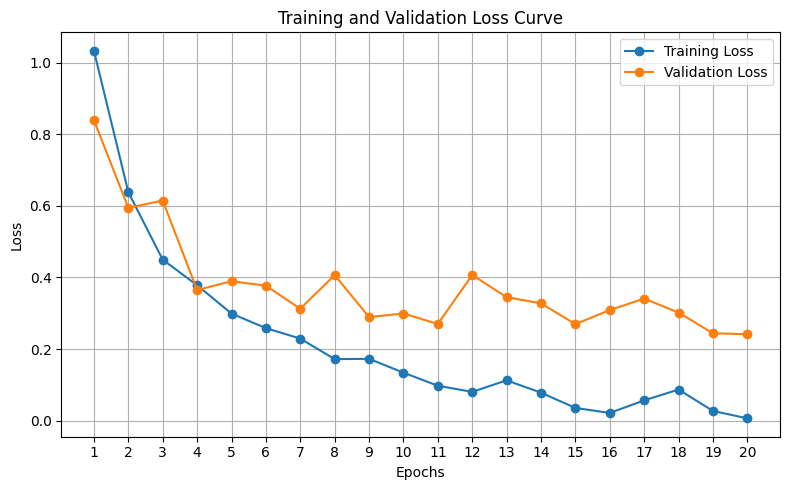

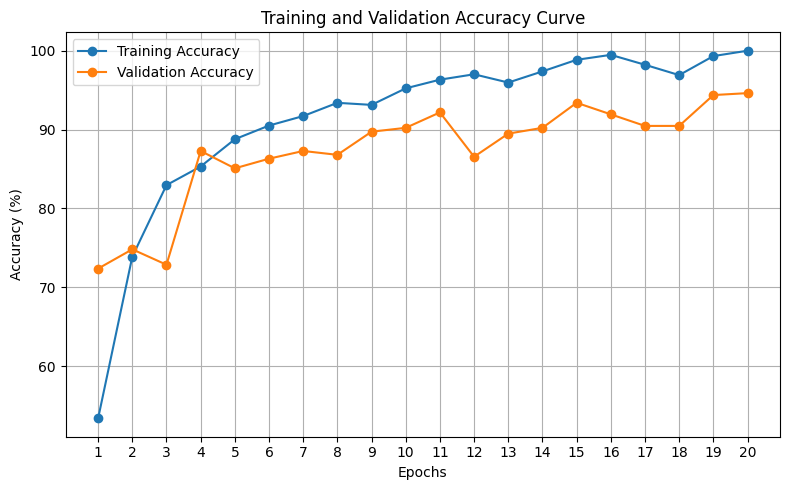

In [65]:
import matplotlib.pyplot as plt

# Get Epoch Numbers
epochs_range = range(1, len(history["train_loss"]) + 1)

# ---------------- LOSS CURVE ----------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    history["train_loss"],
    label="Training Loss",
    marker="o"
)

plt.plot(
    epochs_range,
    history["val_loss"],
    label="Validation Loss",
    marker="o"
)

plt.title("Training and Validation Loss Curve")
plt.xlabel("Epochs")
plt.ylabel("Loss")

plt.legend()
plt.grid(True)

plt.xticks(epochs_range)

plt.tight_layout()
plt.show()


# ---------------- ACCURACY CURVE ----------------

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_range,
    [acc * 100 for acc in history["train_acc"]],
    label="Training Accuracy",
    marker="o"
)

plt.plot(
    epochs_range,
    [acc * 100 for acc in history["val_acc"]],
    label="Validation Accuracy",
    marker="o"
)

plt.title("Training and Validation Accuracy Curve")
plt.xlabel("Epochs")
plt.ylabel("Accuracy (%)")

plt.legend()
plt.grid(True)

plt.xticks(epochs_range)

plt.tight_layout()
plt.show()

# Confusion matrix and classification report

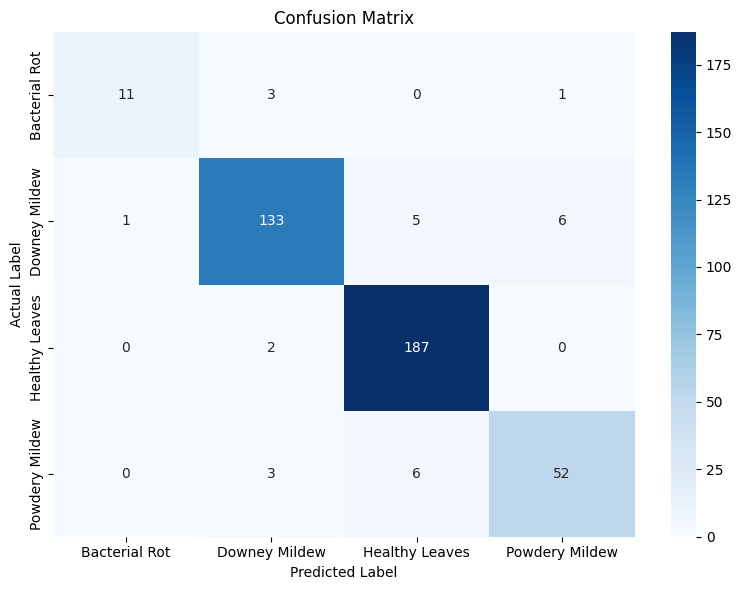


Classification Report:

                precision    recall  f1-score   support

 Bacterial Rot       0.92      0.73      0.81        15
 Downey Mildew       0.94      0.92      0.93       145
Healthy Leaves       0.94      0.99      0.97       189
Powdery Mildew       0.88      0.85      0.87        61

      accuracy                           0.93       410
     macro avg       0.92      0.87      0.89       410
  weighted avg       0.93      0.93      0.93       410



In [66]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix, classification_report

# Model Evaluation
model.eval()

y_true = []
y_pred = []

with torch.no_grad():
    for imgs, labels in test_loader:
        imgs = imgs.to(device)

        outputs = model(imgs)
        predictions = outputs.argmax(1)

        y_true.extend(labels.cpu().numpy())
        y_pred.extend(predictions.cpu().numpy())

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(8, 6))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=test_ds.classes,
    yticklabels=test_ds.classes
)

plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.tight_layout()
plt.show()

# Classification Report
print("\nClassification Report:\n")
print(classification_report(
    y_true,
    y_pred,
    target_names=test_ds.classes
))